# WP12 — Koşullu yerel LLM planı; Aşama A hazır

Kullanıcı V2 yöntemi ve koşullu A→B hazırlığını onayladı. Bu notebook gerçek yeni inference yapmaz. GemmaV1 gerçek ve başarısız; GemmaV2/Qwen NOT_RUN. Yeni normal PowerShell komutu yalnız GemmaV2 S01-R1 için proje genelinde tek üretim slotu kullanabilir.19×3 ve WP13 otomatik açılmaz. Aynı görülen vakada yöntem geliştirme vardır; bağımsız genelleme/klinik doğruluk iddiası yoktur.

In [1]:
from pathlib import Path
import json,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display,Image
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():ROOT=ROOT.parent
Q=ROOT/'reports/qa/WP12/conditional_local_llm_v1'
F=ROOT/'reports/figures/WP12/conditional_local_llm_v1'
def read(p):return json.loads(Path(p).read_text(encoding='utf-8-sig'))
pd.set_option('display.max_colwidth',500);pd.set_option('display.max_columns',15)

plan=read(ROOT/'configs/WP12_CONDITIONAL_LOCAL_LLM_v1.json')
display(pd.DataFrame([{'aşama':k,'kapsam':value} for k,value in plan.items() if k.startswith('stage_')]))
display(pd.DataFrame([read(Q/'preparation_checks.json')]).T.rename(columns={0:'gerçek_hazırlık_durumu'}))


,aşama,kapsam
0,stage_A,"{'method': 'accepted-v2', 'model': 'gemma3:1b-it-q4_K_M', 'digest': 'sha256:97558784bdc9175075a72655bf360b15da17df6b3b9e5182af9f8c0c8e58ba7c', 'max_generation_attempts': 1, 'status': 'NOT_RUN_WAIT_USER_POWERSHELL', 'retry': False}"
1,stage_B,"{'model': 'qwen3:4b-instruct-2507-q4_K_M', 'status': 'NOT_RUN_CONDITION_NOT_TRIGGERED', 'prepare_without_new_method_permission_on': 'completed real Gemma V2 response with schema/application/language/source/task FAIL', 'technical_no_response_is_not_quality_failure': True, 'download': False, 'max_generation_attempts': 1, 'digest': 'NOT_VERIFIED_THIS_STAGE', 'same_S01_sources_question_acceptance': True, 'same_v2_method_unless_mandatory_model_specific_adaptation': True, 'separate_model_bytes_KV_..."
2,stage_C,"{'status': 'PARTIAL_ONLY_V1_REAL_RESULT_AVAILABLE', 'axes': ['schema', 'application', 'Turkish_quality', 'PDF_faithfulness', 'page_quote_alignment', 'unsupported_refusal_missing_information_invention', 'tokens_latency_memory', 'human_review_limits'], 'NOT_RUN_for_unexecuted_experiments': True, 'PENDING_for_unreviewed_semantics': True, 'all_raw_responses_and_failures_preserved': True, 'same_case_method_development_not_independent_generalization': True}"
3,stage_D,"{'19x3_status': 'NOT_AUTHORIZED_TO_AUTOSTART', 'requires_user_results_review': True}"


,gerçek_hazırlık_durumu
stage_A,NOT_RUN_WAIT_USER_POWERSHELL
stage_B,NOT_RUN_CONDITION_NOT_TRIGGERED
stage_C,PARTIAL_REAL_V1_ONLY
stage_D,NO_AUTOSTART_USER_REVIEW_REQUIRED
new_tests_passed,30
accepted_method_tests_passed,36
PowerShell_5_1_syntax_errors,0
single_generation_AST_sites,1
atomic_second_open_blocked,True
real_stage_A_slot_consumed,False


**Yorum:** Koşullu izin diskte kaydedildi; küçük hazırlıklar için tekrar izin istenmeyecek. Kullanıcı PowerShell çıktısı gerekli olduğunda yalnız komut ve gerçek klasör beklenir. GemmaV2 gerçek yanıtında uygulama/dil/görev/kaynak FAIL varsa Qwen hazırlığı açılabilir. Model/API/ölçüm engeli ayrı teknik durumdur; kaynak kalitesi NOT_EVALUABLE kalır. Qwen için mevcut cache/digest, kendi template/tokenizer ve ayrı RAM/VRAM/commit/OS değerlendirmesi gerekir; Gemma'nın düşük eşikleri kopyalanmaz, otomatik düşürülmez.

## Yalnız gerçek kayıtlı sonuç ve NOT_RUN satırları

,model,method,experiment_status,technical_status,schema,application,Turkish_quality,source_faithfulness,primary_page_quote_alignment,human_review,server_prompt_tokens,server_output_tokens,server_total_seconds
0,Gemma3 1B,V1,FAIL,PASS,PASS,FAIL,FAIL,FAIL,FAIL,PENDING_FORMAL_ITEM_REVIEW,919.0,188.0,8.708088
1,Gemma3 1B,V2,NOT_RUN,NOT_RUN,NOT_RUN,NOT_RUN,NOT_RUN,NOT_RUN,NOT_RUN,PENDING,NaN,NaN,NaN
2,Qwen3 4B,V2 with model-specific template only if required,NOT_RUN,NOT_RUN,NOT_RUN,NOT_RUN,NOT_RUN,NOT_RUN,NOT_RUN,PENDING,NaN,NaN,NaN


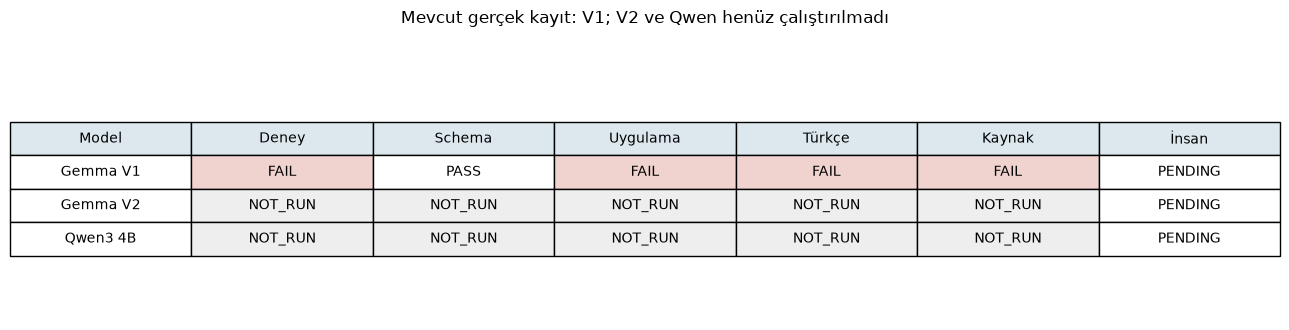

In [2]:

comparison=read(Q/'comparison_current_NOT_FINAL.json')
table=pd.DataFrame(comparison['rows'])
display(table[['model','method','experiment_status','technical_status','schema','application','Turkish_quality','source_faithfulness','primary_page_quote_alignment','human_review','server_prompt_tokens','server_output_tokens','server_total_seconds']])
fig,ax=plt.subplots(figsize=(13,3.4));ax.axis('off')
small=table[['model','experiment_status','schema','application','Turkish_quality','source_faithfulness','human_review']].copy()
small['model']=['Gemma V1','Gemma V2','Qwen3 4B'];small['human_review']='PENDING'
t=ax.table(cellText=small.values,colLabels=['Model','Deney','Schema','Uygulama','Türkçe','Kaynak','İnsan'],loc='center',cellLoc='center')
t.auto_set_font_size(False);t.set_fontsize(10);t.scale(1,2)
for (i,j),cell in t.get_celld().items():
 if i==0:cell.set_facecolor('#dce8ee')
 elif small.iloc[i-1,j]=='FAIL':cell.set_facecolor('#f0d3cf')
 elif small.iloc[i-1,j]=='NOT_RUN':cell.set_facecolor('#eeeeee')
ax.set_title('Mevcut gerçek kayıt: V1; V2 ve Qwen henüz çalıştırılmadı',pad=25)
plt.tight_layout();plt.savefig(F/'current_real_and_NOT_RUN_statuses.png',dpi=160,bbox_inches='tight');plt.show()


**Yorum:** NOT_RUN hücreleri sıfır performans değildir. V1'in önceki insan formu PENDING kalır; kullanıcının başarısızlığı kabul etmesi ayrı user_acknowledged_failure alanındadır. V2 için724 offline token kanıtı vardır fakat henüz server prompt token/yanıt yoktur;724 tabloya gerçek run sonucu olarak yazılmaz. Qwen digest/memory/tokenizer bu aşamada ölçülmüş gibi gösterilmez. JSON ve CSV'de ilk ham model content alanının aynılığı round-trip test edildi.

## Kaynak/id iddiaları — gerçek V1 yanıtı

In [3]:

display(pd.read_csv(Q/'source_vs_claim_current_V1_ONLY.csv')[['topic','source_fact','model_statement_exact','assessment_tr','status']])
print('GERÇEK V1 MODEL CONTENT — AYNEN:')
print(comparison['rows'][0]['model_message_content_exact'])


GERÇEK V1 MODEL CONTENT — AYNEN:
{
  "schema_version": "WP12-local-llm-candidate-v1",
  "status": "refused",
  "refusal_code": "IMAGE_TEXT_UNAVAILABLE",
  "items": [
    {
      "explanation_tr": "The provided text does not contain any information about the product's form or formulation.",
    	"source_scope": "product_identity",
    "statement_kind": "formulation",
    "evidence_ids": [
      "quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe"
    ]
  }
]
}


,topic,source_fact,model_statement_exact,assessment_tr,status
0,ürün,Page1 names Erythromycin Tablets BP 250 mg,The provided text does not contain any information about the product's form or formulation.,Ürün adı/doz açıklanmamış.,OMITTED
1,etkin_madde,Page1: contains active ingredient erythromycin; macrolide antibiotics,The provided text does not contain any information about the product's form or formulation.,Etkin madde ve ilaç sınıfı aktarılmamış.,OMITTED
2,formülasyon,"Page6: red coloured, round, biconvex, enteric-coated tablets",The provided text does not contain any information about the product's form or formulation.,Formülasyon bilgisi yok iddiası açık kaynakla çelişiyor.,CONTRADICTED
3,ambalaj,Page6: blister28/56/84/100; containers21/100/250/500/1000,The provided text does not contain any information about the product's form or formulation.,Ambalaj bilgileri aktarılmamış.,OMITTED
4,belirsizlik,Selected quotes have no image-only or unknown-text qualifier,The provided text does not contain any information about the product's form or formulation.,IMAGE_TEXT_UNAVAILABLE desteklenmiyor; bu sayfalar metin katmanından okunabilir.,UNSUPPORTED_REFUSAL
5,atıf,Cited page1 quote is identity; page6 formulation quote was supplied but not cited,The provided text does not contain any information about the product's form or formulation.,Gerçek quote-ID seçilmiş ancak formulation amacı identity alıntısına bağlanmış.,MISATTRIBUTED
6,dil,Frozen prompt requests Turkish explanation,The provided text does not contain any information about the product's form or formulation.,explanation_tr İngilizce; gerçek Türkçe açıklama yok.,WRONG_LANGUAGE
7,eşdeğerlik,Parent/product equivalence must not be invented,The provided text does not contain any information about the product's form or formulation.,Yeni ana ilaç/ürün eşdeğerliği iddiası yok; bu durum yanlış reti başarılı kılmaz.,NO_EQUIVALENCE_CLAIM
8,yasak_çıktı,"No model score, SHAP, delta-z, ADR or MedDRA generation",The provided text does not contain any information about the product's form or formulation.,Bu yanıtta yeni skor/etiket/yan etki üretilmemiş.,NO_FORBIDDEN_GENERATION


**Yorum:** Kaynak karşılaştırması tek gerçek V1 cümlesinin ayrı konular açısından değerlendirmesidir; dokuz bağımsız model iddiası üretilmiş gibi sayılmaz. V1 hatası değişmez. Yeni V2 yanıt geldiğinde ham/model kaynakları ayrı QA sürümüne yazılacak, önceki yanıt düzeltilmeyecek. Şema/uygulama geçişi Türkçe kaynak sadakati ya da insan onayı değildir.

## Çalıştırıcı ve ölçüm sınırları

In [4]:

display(pd.DataFrame([read(Q/'atomic_slot_test_result.json')]))
display(pd.DataFrame([read(Q/'powershell_5_1_syntax.json')]))
display(pd.DataFrame([read(Q/'preparation_memory_snapshot.json')]))


,real_stage_A_slot_exists,first_claim_created,inference,test_only,first_claim_unchanged,second_claim_blocked
0,False,True,0,True,True,True


,parser,runner_sha256,runner_executed,errors,generation_call_AST_count,error_count
0,5.1.26100.9711,f3f639c8c0f425a0e00b615d19fef010aaf8aae9f91135e5fb07df18553f45f1,False,[],1,0


,measurement_status,inference,GPU,memory,scope,API_attempts
0,COMPLETE,0,"{'total_MiB': 4096, 'name': 'NVIDIA GeForce GTX 1650 Ti', 'free_MiB': 3935}","{'load_percent': 76, 'at': '2026-11-08T07:39:43.6146225+03:00', 'low_memory_notification': False, 'available_bytes': 1861865472, 'total_bytes': 7968415744, 'commit_available_bytes': 12008837120}",PREPARATION_SNAPSHOT_NOT_ADMISSION_GUARANTEE,0


**Yorum:** Gerçek generation slotu tüketilmedi; ayrı TEST_ONLY dosyasında ilk CreateNew başarılı/ikinci engelli. PowerShell5.1 parse0hata, bir PostAsync.30 yeni yürütücü/koşul +36 kabul edilmiş yöntem testi geçti. AppContainer'da API'den önce durulur. Başlangıç1,5GiB RAM/1GiB GPU/3GiB commit, OSfalse; runtime0,75GiB RAM/1GiB commit/OS alarmı ve60s timeout aynı. Snapshot bir çalışma garantisi değildir; gerçek kullanıcı preflight'ında tekrar ölçülür. Bellek/kimlik/kaynak/token/şema kapılarından sonra atomik tek-slot claim alınır; timeout veya kalite hatasında claim otomatik sıfırlanmaz. Slot alındıktan sonra başarısızlık bile tekrar hakkı yaratmaz. Bu dosyaya reset/force/kopyalama yönergesi yoktur.

**Durdurma noktası:** Normal kullanıcı PowerShell'inde yalnız Aşama A komutu. Çıktı klasörü bekleniyor. Qwen hazırlığı koşula bağlı; 19×3 sonuç incelemesi olmadan başlamaz; yeni eğitim/yayın/WP13 yok.